## 5. 測定誤差のある線形モデル
### 図5.1, 5.2, 5.3
Deming回帰

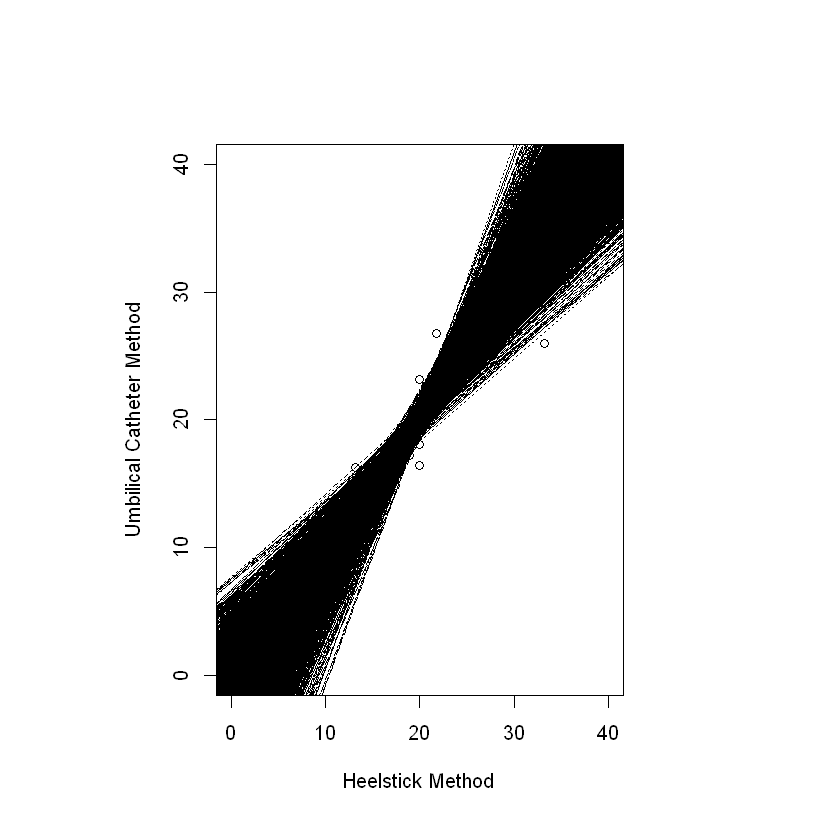

In [24]:
par(bg = "white")
# appendix B.4 (Figure 5.1, 5.2, 5.3)
#
kana <- read.csv('./src/table_5_1.csv')
# kana <- scan("hand.s", list(x=0, y=0))
par(mar=c(6, 9, 6, 9))
indx <- 1:20
sx2 <- var(kana$x)
sy2 <- var(kana$y)
sxy <- var(kana$x, kana$y)
mx <- mean(kana$x)
my <- mean(kana$y)
beta0 <- (sy2 - sx2 + sqrt((sy2 - sx2)^2 + 4*sxy*sxy)) / 2 / sxy
alpha0 <- my - mx*beta0
plot(kana$x, kana$y, pch=1, xlim=c(0, 40), ylim=c(0, 40),
     xlab="Heelstick Method", ylab="Umbilical Catheter Method")
abline(alpha0, beta0, lty=1, col=2)

nb <- 2000

beta <- rep(0, nb)
alpha <- rep(0, nb)
for (i in 1:nb) {
  ind <- sample(indx, replace=T)
  xx <- kana$x[ind]
  yy <- kana$y[ind]

  sx2 <- var(xx)
  sy2 <- var(yy)
  sxy <- var(xx, yy)
  mx <- mean(xx)
  my <- mean(yy)
  beta[i] <- (sy2 - sx2 + sqrt((sy2 - sx2)^2 + 4*(sxy*sxy))) / (2*sxy)
  alpha[i] <- my - mx*beta[i]
  abline(alpha[i], beta[i], lty=i)
}


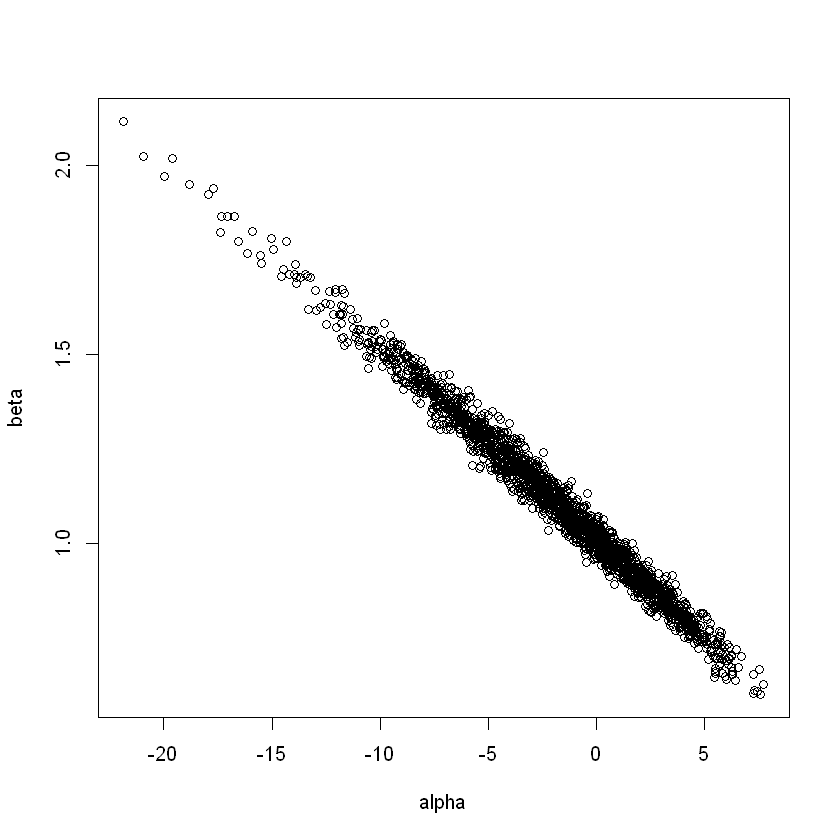

In [25]:
par(bg = "white")
plot(alpha, beta)

In [26]:
cx <- qnorm(length(beta[beta <= beta0]) / nb)
p1 <- pnorm(-1.96 + 2*cx)
p2 <- pnorm(1.96 + 2*cx)
betaL <- quantile(beta, p1) # confidence limits for beta
betaU <- quantile(beta, p2)

print(betaL)
print(betaU)

 1.92099% 
0.7126733 
96.78182% 
 1.544433 


In [27]:
cx <- qnorm(length(alpha[alpha <= alpha0]) / nb)
p1 <- pnorm(-1.96 + 2*cx)
p2 <- pnorm(1.96 + 2*cx)
alphaL <- quantile(alpha, p1) # confidence limits for alpha
alphaU <- quantile(alpha, p2)

print(alphaL)
print(alphaU)

3.328349% 
  -10.618 
98.14841% 
 5.732889 


### 問題
#### 問題5.4

E(y) = -1.160086 + 1.069772 * E(x)

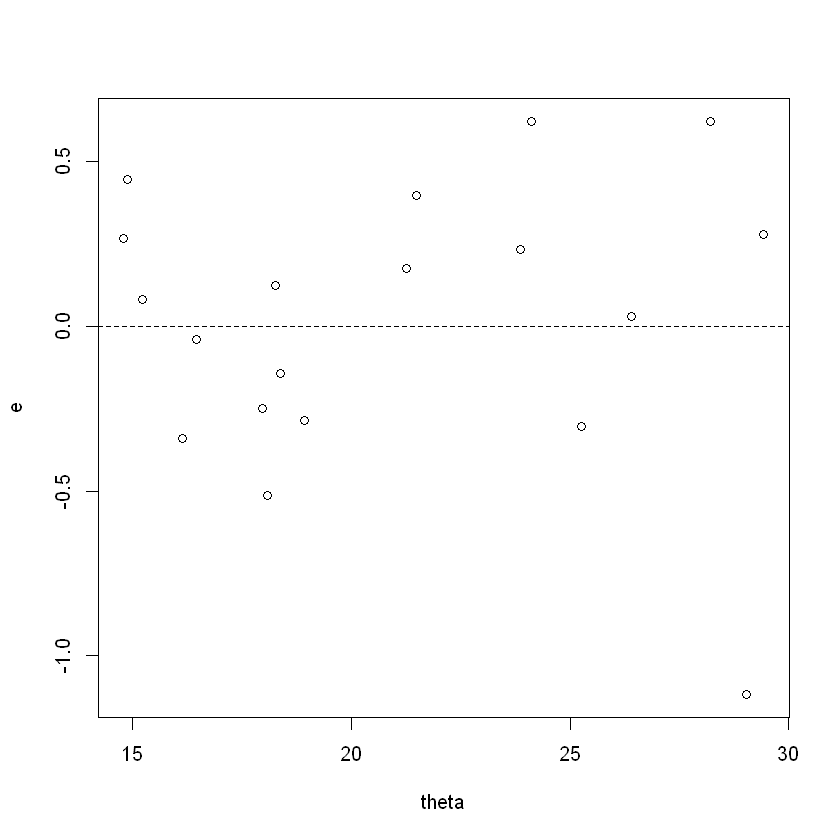

In [28]:
df <- read.csv('./src/table_5_1.csv')

lambda <- 1

sxx <- var(df$x)
syy <- var(df$y)
sxy <- cov(df$x, df$y)

beta <- (syy - lambda*sxx + sqrt((syy - lambda*sxx)^2 + 4*lambda*sxy^2)) / (2*sxy) # (5.14)
alpha <- mean(df$y) - beta*mean(df$x) # (5.15)
e <- (df$y - alpha - beta*df$x) / sqrt(sxx*(beta^2+lambda)) # (5.34)

cat('E(y) =', alpha, '+', beta, '* E(x)')

theta <- (beta*df$y + lambda*df$x - alpha*beta) / (beta^2 + lambda)

par(bg = "white")
plot(theta, e); abline(h = 0, lty = 2)

#### 問題5.5

In [29]:
df <- read.csv('./src/table_5_4.csv')

lambda <- sum((df$n1 - df$n2)^2) / sum((df$s1 - df$s2)^2) # (5.8)

df$x <- (df$s1 + df$s2) / 2
df$y <- (df$n1 + df$n2) / 2

sxx <- var(df$x)
syy <- var(df$y)
sxy <- cov(df$x, df$y)

beta <- (syy - lambda*sxx + sqrt((syy - lambda*sxx)^2 + 4*lambda*sxy^2)) / (2*sxy) # (5.14)
alpha <- mean(df$y) - beta*mean(df$x) # (5.15)

cat('E(y) =', alpha, '+', beta, '* E(x)')

E(y) = -6.628681 + 0.9905546 * E(x)

#### 問題5.6
解決せず．

In [30]:
df <- read.csv('./src/table_5_1.csv')

lambda <- 1

sxx <- var(df$x)
syy <- var(df$y)
sxy <- cov(df$x, df$y)

beta <- (syy - lambda*sxx + sqrt((syy - lambda*sxx)^2 + 4*lambda*sxy^2)) / (2*sxy) # (5.14)
alpha <- mean(df$y) - beta*mean(df$x) # (5.15)

theta <- (beta*df$y + lambda*df$x - alpha*beta) / (beta^2 + lambda)

delta <- df$x - theta
epsilon <- df$y - alpha - beta*theta

data <- data.frame(delta, epsilon)

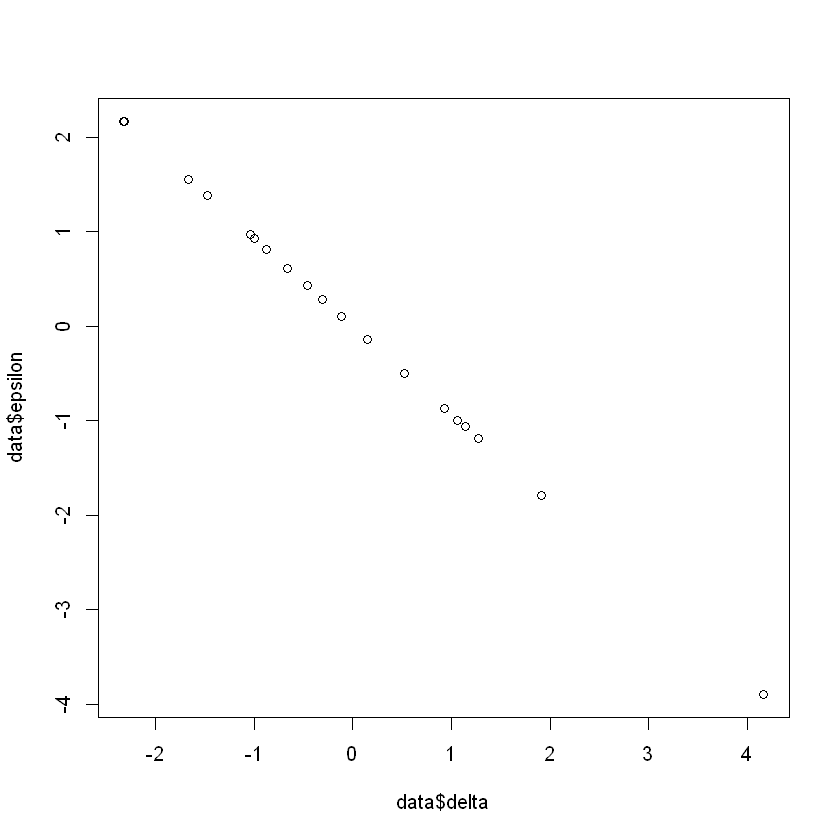

In [31]:
par(bg = "white")
plot(data$delta, data$epsilon)

In [32]:
library(boot)

calc_beta <- function(data, i) {
  d_sample <- data[i, "delta"]
  e_sample <- data[i, "epsilon"]
  sxx <- var(d_sample)
  syy <- var(e_sample)
  sxy <- cov(d_sample, e_sample)
  lambda <- 1
  beta <- (syy - lambda*sxx + sqrt((syy - lambda*sxx)^2 + 4*lambda*sxy^2)) / (2*sxy) # (5.14)
  return(beta)
}

boot_results <- boot(data = data, statistic = calc_beta, R = 2000)
boot_ci <- boot.ci(boot_results, type = "bca")
print(boot_ci)

BOOTSTRAP CONFIDENCE INTERVAL CALCULATIONS
Based on 2000 bootstrap replicates

CALL : 
boot.ci(boot.out = boot_results, type = "bca")

Intervals : 
Level       BCa          
95%   (-0.9348, -0.9348 )  
Calculations and Intervals on Original Scale
